# 01 - Data Overview

Goal: understand the structure and quality of the raw dataset.

This notebook is read-only: it does not modify the data.

Source: [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) (UCI Machine Learning Repository)

Data: run `make data` from the project root to download the dataset into `data/raw/` (see the README for the full setup).

In [1]:
import pandas as pd

DATA_PATH = "../data/raw/default_of_credit_card_clients.xls"
TARGET = "default payment next month"
ID_COL = "ID"

PAY_COLS = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]

In [2]:
df = pd.read_excel(DATA_PATH, header=1, engine="calamine")
print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Structure

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

## 2. Data dictionary

The full description of the dataset (variables, value codes, source and license) is in [docs/dataset.md](../docs/dataset.md).

## 3. Data quality

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows (excluding ID):", df.drop(columns=ID_COL).duplicated().sum())

Missing values: 0
Duplicated rows (excluding ID): 35


## 4. ID column

Record identifier. It is not a feature and carries no information about the client.

In [5]:
print("Unique IDs:", df[ID_COL].nunique(), "of", len(df))
print("Min / max:", df[ID_COL].min(), "/", df[ID_COL].max())
print("Sorted ascending:", df[ID_COL].is_monotonic_increasing)

Unique IDs: 30000 of 30000
Min / max: 1 / 30000
Sorted ascending: True


## 5. Credit limit and demographics (X1-X5: LIMIT_BAL, SEX, EDUCATION, MARRIAGE, AGE)

See the data dictionary above for the meaning of each column and its codes.

### 5.1 LIMIT_BAL (X1)

Amount of given credit in NT dollars (individual and family/supplementary credit).

In [6]:
df["LIMIT_BAL"].describe().round(1)

count      30000.0
mean      167484.3
std       129747.7
min        10000.0
25%        50000.0
50%       140000.0
75%       240000.0
max      1000000.0
Name: LIMIT_BAL, dtype: float64

### 5.2 SEX (X2)

1 = male, 2 = female.

In [7]:
df["SEX"].value_counts().sort_index()

SEX
1    11888
2    18112
Name: count, dtype: int64

### 5.3 EDUCATION (X3)

1 = graduate school, 2 = university, 3 = high school, 4 = others.

In [8]:
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

**Observation:** the values 0, 5 and 6 appear in the data, but they are not documented on the UCI page, which lists only codes 1 to 4. Counts: 0 -> 14, 5 -> 280, 6 -> 51 rows (345 rows in total). They are left unchanged in this notebook; how to handle them is decided in the cleaning notebook.

### 5.4 MARRIAGE (X4)

1 = married, 2 = single, 3 = others.

In [9]:
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

**Observation:** the value 0 appears in the data, but it is not documented on the UCI page, which lists only codes 1 to 3. Count: 0 -> 54 rows. It is left unchanged in this notebook; how to handle it is decided in the cleaning notebook.

### 5.5 AGE (X5)

Age in years.

In [10]:
df["AGE"].describe().round(1)

count    30000.0
mean        35.5
std          9.2
min         21.0
25%         28.0
50%         34.0
75%         41.0
max         79.0
Name: AGE, dtype: float64

## 6. Repayment status (X6-X11: PAY_0, PAY_2 ... PAY_6)

Monthly repayment status, September to April. See the data dictionary above for the documented codes.

In [11]:
pay_counts = pd.DataFrame({c: df[c].value_counts() for c in PAY_COLS})
pay_counts.sort_index().fillna(0).astype(int)

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


**Observation:** the codes -2 and 0 appear in every PAY column but are not documented on the UCI page, and the documented code 9 never appears. Code 1 is frequent in PAY_0 (3,688 rows) but almost absent in PAY_2 to PAY_6 (28, 4, 2, 0 and 0 rows). Values are left unchanged in this notebook.

## 7. Bill statement amounts (X12-X17: BILL_AMT1 ... BILL_AMT6)

Monthly bill statement amounts in NT dollars, September to April.

In [12]:
df[BILL_COLS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
BILL_AMT1,30000.0,51223.3,73635.9,-165580.0,3558.8,22381.5,67091.0,964511.0
BILL_AMT2,30000.0,49179.1,71173.8,-69777.0,2984.8,21200.0,64006.2,983931.0
BILL_AMT3,30000.0,47013.2,69349.4,-157264.0,2666.2,20088.5,60164.8,1664089.0
BILL_AMT4,30000.0,43262.9,64332.9,-170000.0,2326.8,19052.0,54506.0,891586.0
BILL_AMT5,30000.0,40311.4,60797.2,-81334.0,1763.0,18104.5,50190.5,927171.0
BILL_AMT6,30000.0,38871.8,59554.1,-339603.0,1256.0,17071.0,49198.2,961664.0


**Observation:** every BILL_AMT column contains negative values (between 590 and 688 rows per column), and the distributions are strongly right-skewed. Values are left unchanged in this notebook.

## 8. Previous payment amounts (X18-X23: PAY_AMT1 ... PAY_AMT6)

Monthly payment amounts in NT dollars, September to April.

In [13]:
df[PAY_AMT_COLS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
PAY_AMT1,30000.0,5663.6,16563.3,0.0,1000.0,2100.0,5006.0,873552.0
PAY_AMT2,30000.0,5921.2,23040.9,0.0,833.0,2009.0,5000.0,1684259.0
PAY_AMT3,30000.0,5225.7,17607.0,0.0,390.0,1800.0,4505.0,896040.0
PAY_AMT4,30000.0,4826.1,15666.2,0.0,296.0,1500.0,4013.2,621000.0
PAY_AMT5,30000.0,4799.4,15278.3,0.0,252.5,1500.0,4031.5,426529.0
PAY_AMT6,30000.0,5215.5,17777.5,0.0,117.8,1500.0,4000.0,528666.0


**Observation:** in every PAY_AMT column the median is far below the mean and the maximum is above 400,000, so the distributions are strongly right-skewed. Values are left unchanged in this notebook.

## 9. Target (Y: default payment next month)

Binary target: 1 = default, 0 = no default.

In [14]:
counts = df[TARGET].value_counts()
share = df[TARGET].value_counts(normalize=True)
print(pd.DataFrame({"count": counts, "share": share.round(4)}))

                            count   share
default payment next month               
0                           23364  0.7788
1                            6636  0.2212


## 10. Visualizations

Univariate views of the columns, in dataset order. The ID column is only an identifier and is not plotted. Relationships between features and the target are covered in the EDA notebook.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

SEX_LABELS = {1: "male", 2: "female"}
EDUCATION_LABELS = {1: "graduate school", 2: "university", 3: "high school", 4: "others"}
MARRIAGE_LABELS = {1: "married", 2: "single", 3: "others"}
TARGET_LABELS = {0: "no default", 1: "default"}


def plot_coded_counts(data, col, labels, title):
    """Bar chart of documented codes with counts above the bars and a legend of code meanings."""
    counts = data[col].value_counts().reindex(list(labels), fill_value=0)
    excluded = len(data) - counts.sum()
    palette = sns.color_palette("deep", len(labels))

    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar([str(code) for code in counts.index], counts.values, color=palette)
    ax.bar_label(bars, padding=2)
    ax.margins(y=0.12)
    handles = [
        plt.Rectangle((0, 0), 1, 1, color=palette[i], label=f"{code} = {name}")
        for i, (code, name) in enumerate(labels.items())
    ]
    ax.legend(handles=handles, title=col)
    ax.set_xlabel(col)
    ax.set_ylabel("count")
    if excluded > 0:
        title = f"{title}\n(undocumented codes not shown: {excluded} rows)"
    ax.set_title(title)
    plt.show()


def plot_hist_grid(data, cols, ncols=3, bins=50, log_y=False, discrete=False):
    """One histogram per column, arranged in a grid."""
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)
    for ax, col in zip(axes.ravel(), cols):
        options = {"discrete": True} if discrete else {"bins": bins}
        sns.histplot(data[col], ax=ax, **options)
        ax.set_title(col)
        ax.set_xlabel("")
        if log_y:
            ax.set_yscale("log")
    for ax in axes.ravel()[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

### 10.1 LIMIT_BAL (X1)

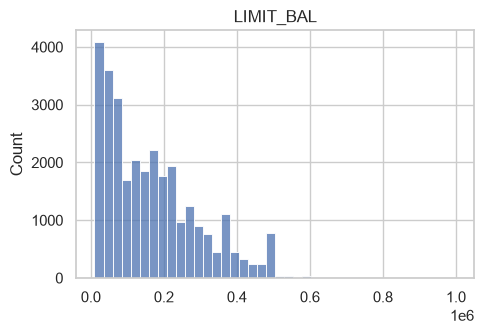

In [16]:
plot_hist_grid(df, ["LIMIT_BAL"], ncols=1, bins=40)

### 10.2 SEX (X2)

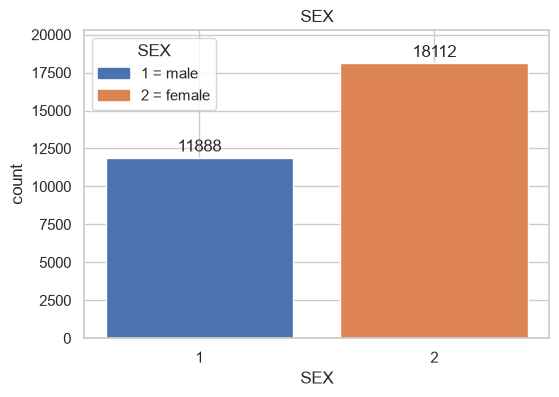

In [17]:
plot_coded_counts(df, "SEX", SEX_LABELS, "SEX")

### 10.3 EDUCATION (X3)

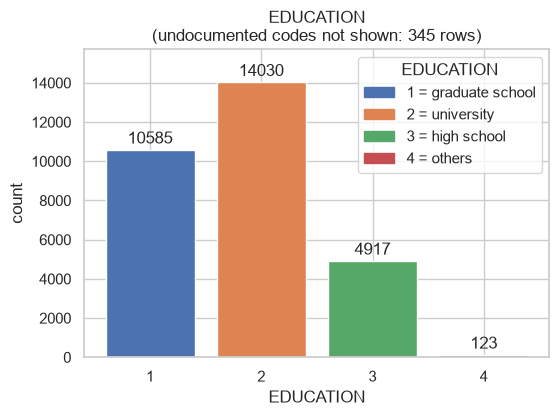

In [18]:
plot_coded_counts(df, "EDUCATION", EDUCATION_LABELS, "EDUCATION")

### 10.4 MARRIAGE (X4)

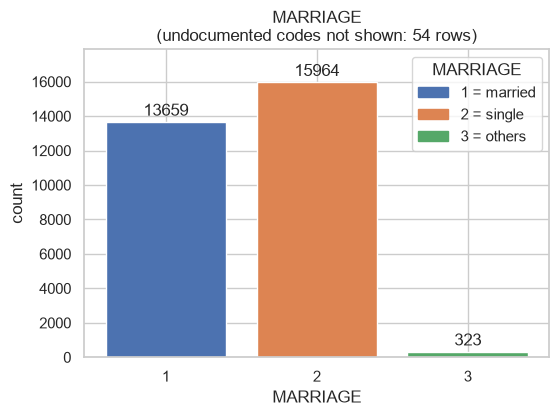

In [19]:
plot_coded_counts(df, "MARRIAGE", MARRIAGE_LABELS, "MARRIAGE")

### 10.5 AGE (X5)

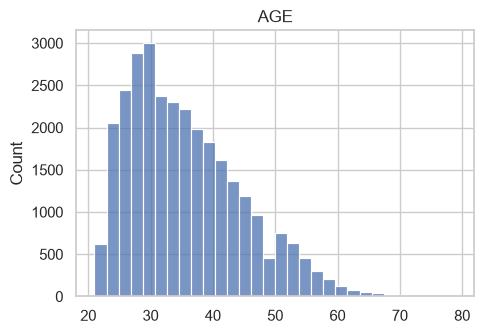

In [20]:
plot_hist_grid(df, ["AGE"], ncols=1, bins=30)

### 10.6 Repayment status (X6-X11)

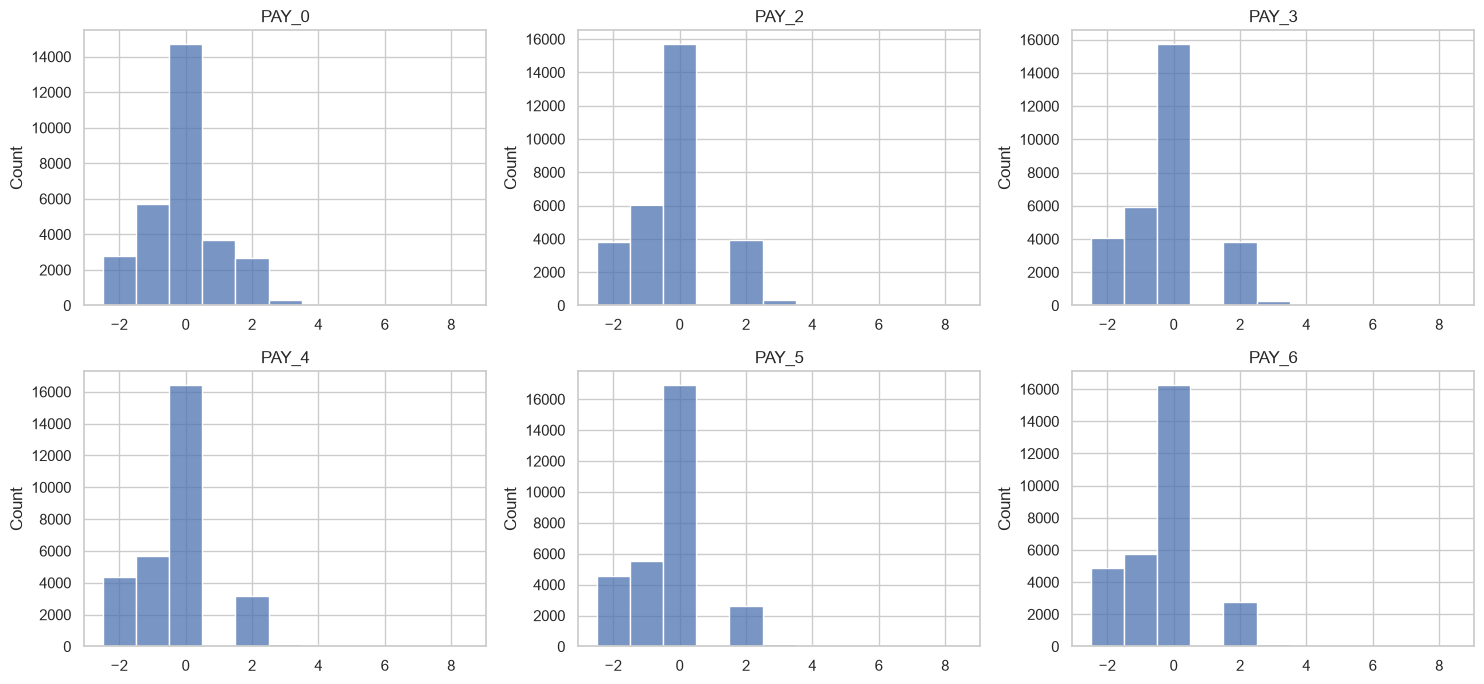

In [21]:
plot_hist_grid(df, PAY_COLS, discrete=True)

### 10.7 Bill statement amounts (X12-X17)

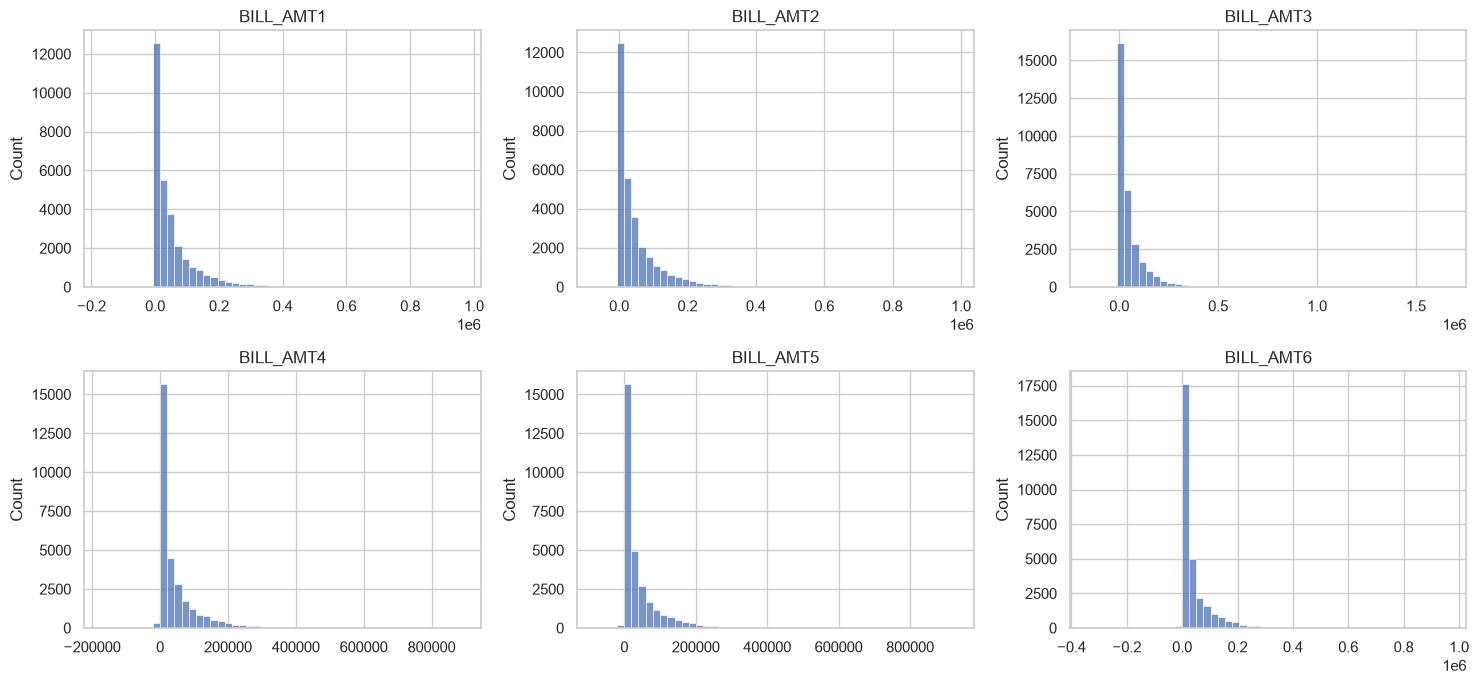

In [22]:
plot_hist_grid(df, BILL_COLS)

### 10.8 Previous payment amounts (X18-X23)

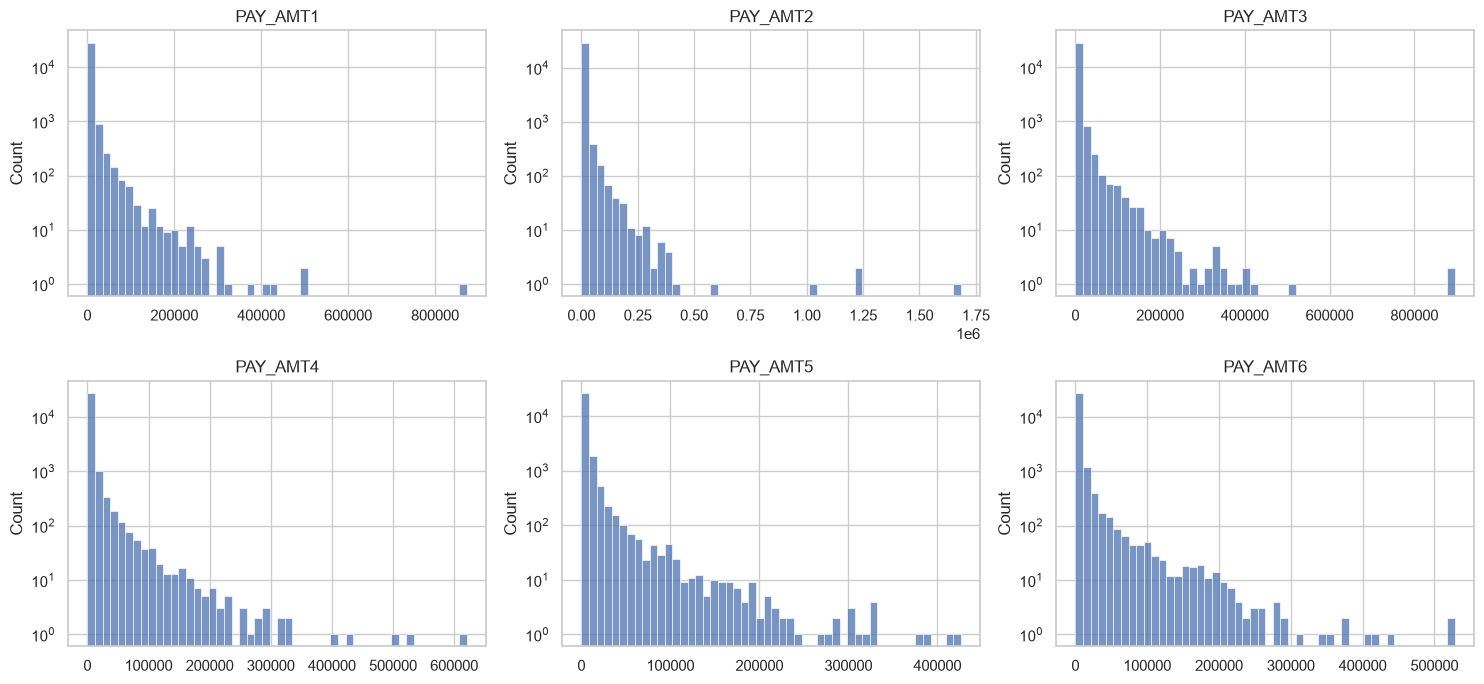

In [23]:
plot_hist_grid(df, PAY_AMT_COLS, log_y=True)

### 10.9 Target (Y)

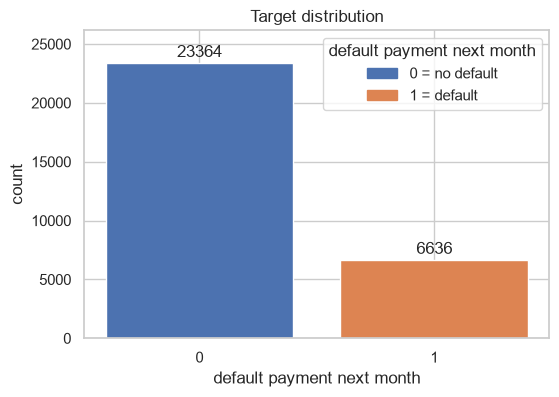

In [24]:
plot_coded_counts(df, TARGET, TARGET_LABELS, "Target distribution")

## 11. Summary of findings

- Shape: 30,000 rows, 25 columns (ID, 23 features, target). No missing values.
- Duplicated rows (excluding ID): 35.
- Target is imbalanced: 6,636 defaults (22.12%) vs 23,364 non-defaults (77.88%).
- EDUCATION contains the undocumented codes 0, 5 and 6 (14, 280 and 51 rows; 345 rows in total).
- MARRIAGE contains the undocumented code 0 (54 rows).
- PAY_* columns contain the undocumented codes -2 and 0. Together they cover between 17,496 rows (PAY_0) and 21,493 rows (PAY_5) per column. The documented code 9 never appears.
- Code 1 (one-month delay) is frequent in PAY_0 (3,688 rows) but almost absent in PAY_2 to PAY_6 (28, 4, 2, 0 and 0 rows). This difference is worth checking in the EDA notebook.
- BILL_AMT columns contain negative values: between 590 and 688 rows per column.
- PAY_AMT and BILL_AMT columns are strongly right-skewed with large outliers.
- PAY_0 breaks the naming pattern (there is no PAY_1).

These points are handled in the cleaning notebook. This notebook does not change the data.